<a href="https://colab.research.google.com/github/jess22jess/Ing_Fin/blob/main/Modelo_Econom%C3%A9trico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODELO ECONOMÉTRICO

Para comprobar cuantitativamente la hipótesis planteada, se implementó un modelo econométrico de regresión lineal múltiple mediante la técnica de **Mínimos Cuadrados Ordinarios** (OLS).

El objetivo de este modelo es aislar el efecto que tiene la variable **Es_marca_propia** (que identifica a los medicamentos genéricos de Farmacias del Ahorro) sobre el **Precio_actual** de los productos, controlando al mismo tiempo por otros factores que podrían influir en el costo, como la *Requiere_receta*, el *Numero_resenas* y las *Existencias_reportadas*.

A través de esta técnica, no solo buscamos estimar la diferencia de precio promedio entre un genérico y una marca de patente, sino también determinar si dicha diferencia es *estadísticamente significativa* (a través del valor p o **p-value**), permitiendo validar o rechazar científicamente la premisa del ahorro del **60%** planteada en el proyecto.


In [34]:
import pandas as pd # trae la herramienta para manejar tablas de datos
import statsmodels.api as sm #trae la herramienta especializada en estadística y econometría (la que hace las regresiones.
import matplotlib.pyplot as plt # funciona para hacer las gráficas
import seaborn as sns # funciona para hacer las gráficas

Está celda se utiliza para leer el código

In [35]:
df = pd.read_excel("EXCEL Farmacia.xlsx", sheet_name="Productos") # Abre el archivo de Excel, entra a la pestaña "Productos"
                                                                  # y guarda toda la información en la variable df
print("Datos cargados. Total de filas:", len(df))  # Confirma cuántos datos se cargaron

Datos cargados. Total de filas: 5500


# Limpieza de datos

Dado que los modelos de regresión solo aceptan variables numéricas, se seleccionaron exclusivamente las columnas relevantes para el análisis (Precio_actual, Es_marca_propia, Requiere_receta, Numero_resenas y Existencias_reportadas).

Posteriormente, se aplicó una conversión forzosa a tipo numérico a cada una de estas columnas. En caso de encontrar celdas vacías (valores nulos), se rellenaron con un valor de cero (0) para evitar que el modelo arrojara errores o descartara registros completos.

Finalmente, las variables booleanas (Es_marca_propia y Requiere_receta), que originalmente podían venir como valores lógicos **(True/False)**, se convirtieron a variables dicotómicas **(1 y 0)**. Esto garantiza que el modelo estadístico interprete correctamente la presencia o ausencia de estas características.

In [36]:
columnas = ['Precio_actual', 'Es_marca_propia', 'Requiere_receta', 'Numero_resenas', 'Existencias_reportadas']

# Convertimos a números y rellenamos vacíos con 0

1. **df_limpio = df[columnas].copy()** De tu tabla original gigante, toma solo las columnas que anotamos en la lista. Luego, con .copy(), crea una copia exacta e independiente y la guarda en una nueva variable llamada **df_limpio**.

2. **for col in columnas:** Inicia un bucle. Le dice al programa que va a repetir las siguientes instrucciones para cada una de las columnas que están en la lista. Primero lo hará con Precio_actual, luego con Es_marca_propia, y así sucesivamente.

3. **df_limpio[col] = pd.to_numeric(df_limpio[col], errors='coerce').fillna(0):**

El proceso se divide en tres partes:

* pd.to_numeric(df_limpio[col], ...): Le dice a Python: "Toma la columna en la que estamos (ej. Precio_actual) y oblígala a ser un número".

* errors='coerce': "Si encuentras algo que NO sea un número (como un espacio vacío, un texto, o un guion), no me marques error y tires todo el programa; mejor conviértelo en un valor nulo (NaN)".

* .fillna(0): "Ahora que los valores raros son nulos (NaN), rellénalos todos con un 0".

In [37]:
df_limpio = df[columnas].copy()
for col in columnas:
    df_limpio[col] = pd.to_numeric(df_limpio[col], errors='coerce').fillna(0)

Aseguramos que las de 1 y 0 sean enteros

In [38]:
df_limpio['Es_marca_propia'] = df_limpio['Es_marca_propia'].astype(int)
df_limpio['Requiere_receta'] = df_limpio['Requiere_receta'].astype(int)

Los datos ya están limpios

---

Y es variable dependiente y X variables independientes.

In [39]:
Y = df_limpio['Precio_actual']
X = df_limpio[['Es_marca_propia', 'Requiere_receta', 'Numero_resenas', 'Existencias_reportadas']]

Agregamos una columna extra de 1s para la regresión.

In [40]:
X = sm.add_constant(X)

* **sm.OLS(Y, X):** Mínimos Cuadrados Ordinarios. Es el nombre del método estadístico que busca la línea recta que pase lo más cerca posible de todos los puntos.

* **.fit():** Es el comando que le dice al modelo que haga los cálculos con los datos".

* **modelo = ...:** Guarda todos esos cálculos (los coeficientes, los p-values, etc.) dentro de una variable llamada modelo, para que luego puedas imprimir la tabla con *modelo.summary().*



In [41]:
modelo = sm.OLS(Y, X).fit()

/tmp/ipykernel_545/3696483049.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  modelo = sm.OLS(Y, X).fit()


# Resultados

In [42]:
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:          Precio_actual   R-squared:                       0.047
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     134.9
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           6.18e-58
Time:                        16:24:52   Log-Likelihood:                -43438.
No. Observations:                5500   AIC:                         8.688e+04
Df Residuals:                    5497   BIC:                         8.690e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                    577

# GRÁFICAS

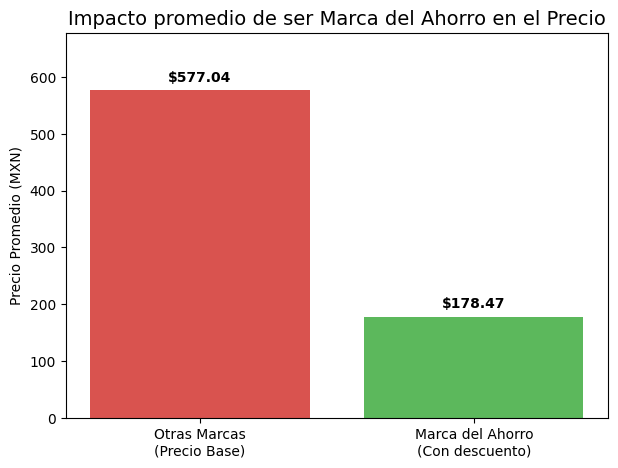

In [43]:
# Extraemos los datos del modelo
intercepto = modelo.params['const']
coef_marca = modelo.params['Es_marca_propia']

# Etiquetas y valores
etiquetas = ['Otras Marcas\n(Precio Base)', 'Marca del Ahorro\n(Con descuento)']
valores = [intercepto, intercepto + coef_marca]

# Crea el gráfico
plt.figure(figsize=(7, 5))
barras = plt.bar(etiquetas, valores, color=['#d9534f', '#5cb85c'])
plt.title('Impacto promedio de ser Marca del Ahorro en el Precio', fontsize=14)
plt.ylabel('Precio Promedio (MXN)')
plt.ylim(0, max(valores) + 100)

# Poner el valor arriba de cada barra
for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 10, f"${yval:.2f}", ha='center', va='bottom', fontweight='bold')

plt.show()

# Gráfica de Barras
Muestra el impacto real de la marca en el precio. El modelo estima que un producto de marca de patente tiene un precio base promedio de 577.04 MXN. Sin embargo, si el producto pertenece a la línea 'Marca del Ahorro', el precio cae 398.57 pesos, dejando un costo final de 178.47 MXN. Esta diferencia equivale a un ahorro del **69%**, lo que confirma de manera visual y matemática la hipótesis inicial de que los genéricos son más de un 60% más baratos.

/tmp/ipykernel_545/3548640753.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Es_marca_propia', y='Precio_actual', data=df_limpio, palette=['#d9534f', '#5cb85c'])


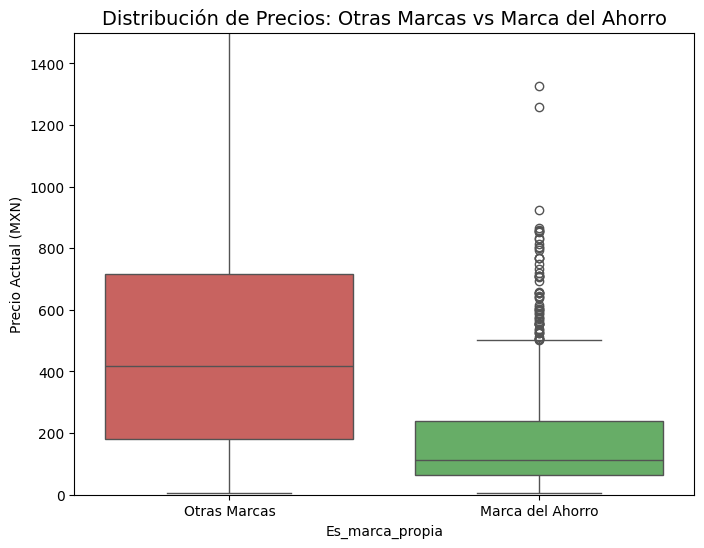

In [46]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Es_marca_propia', y='Precio_actual', data=df_limpio, palette=['#d9534f', '#5cb85c'])
plt.title('Distribución de Precios: Otras Marcas vs Marca del Ahorro', fontsize=14)
plt.ylabel('Precio Actual (MXN)')
plt.xticks([0, 1], ['Otras Marcas', 'Marca del Ahorro'])
plt.ylim(0, 1500)
plt.show()

#Diagrama de Caja
Muestra una clara diferencia en la distribución de los precios entre ambas categorías.

Los productos de **Otras Marcas (0)** presentan una mediana cercana a los 420 MXN, con un rango intercuartílico (la caja) que abarca desde aproximadamente 180 hasta 710 pesos, reflejando una **gran dispersión y presencia de productos de alto costo**.

Por el contrario, la **Marca del Ahorro (1)** muestra una mediana mucho menor, ubicada alrededor de los 100 MXN, y una caja más compacta que se concentra en la parte baja de la escala.

*Esta distribución evidencia no solo que los genéricos son más baratos en promedio, sino que sus precios son mucho más homogéneos y accesibles en comparación con la alta variabilidad de las marcas de patente.*

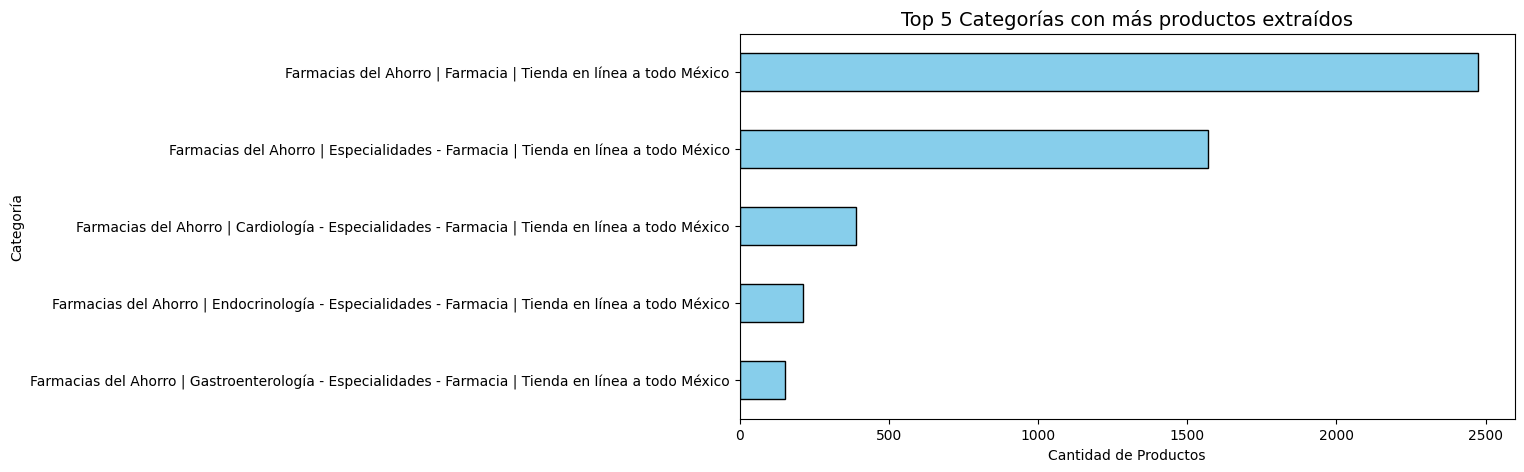

In [45]:
# Cuenta los productos por categoría y saca las 5 más grandes
top_categorias = df['Categoria_origen'].value_counts().head(5)

plt.figure(figsize=(10, 5))
# Gráfico de barras horizontales
top_categorias.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Top 5 Categorías con más productos extraídos', fontsize=14)
plt.xlabel('Cantidad de Productos')
plt.ylabel('Categoría')
plt.gca().invert_yaxis() # Para que la más grande salga hasta arriba
plt.show()

# Gráfico de Barras Horizontales
Muestra el volumen de productos extraídos según su categoría de origen. Se observa que la categoría general de **"Farmacia"** concentró el mayor número de registros **(más de 2,400 productos)**.

Seguida por **"Especialidades" (cerca de 1,600).**

Las categorías específicas como **Cardiología, Endocrinología y Gastroenterología **aportaron volúmenes menores (**entre 100 y 400** productos cada una).

*Esto demuestra que el scraper logró abarcar tanto el catálogo general como las especialidades médicas de la tienda en línea.*

# MATRIZ DE CORRELACIÓN

Seleccionamos las columnas que nos interesan

In [ ]:
columnas_corr = ['Precio_actual', 'Precio_anterior', 'Es_marca_propia',
                 'Requiere_receta', 'Numero_resenas', 'Existencias_reportadas', 'Puntuacion_busqueda']

Calculamos la correlación (limpiando nulos)


In [ ]:
df_corr = df[columnas_corr].apply(pd.to_numeric, errors='coerce').fillna(0)
matriz = df_corr.corr()

# Graficamos

Nota:

**sns.heatmap:** Dibuja el mapa de calor.
* **'annot=True'** pone los números dentro de los cuadros
* **'cmap'** elige los colores (azul=negativo, rojo=positivo)
* **'fmt=".2f"'** los redondea a 2 decimales  
* **'linewidths'** hace las líneas divisorias.

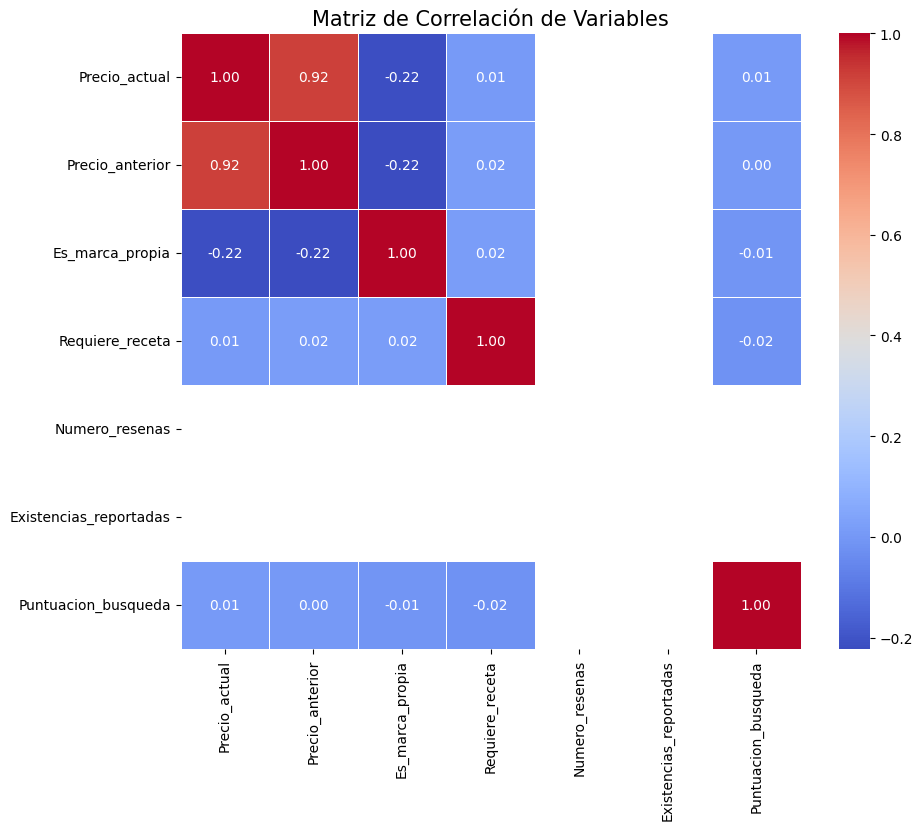

In [47]:
plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables', fontsize=15)  # Escribe el título de la gráfica en la parte superior.
plt.show()

El **mapa de calor** revela las relaciones lineales entre las variables analizadas.

*Se destaca una **correlación positiva** muy fuerte (0.92) entre el Precio_actual y el Precio_anterior*, lo cual es lógico y confirma la consistencia de los datos extraídos (los precios no han sufrido variaciones drásticas).

Por otro lado, se observa una *correlación negativa moderada (-0.22) entre el Precio_actual y la variable Es_marca_propia*. Esto indica que, a medida que un producto pertenece a la marca propia de la tienda, su precio tiende a **disminuir**, lo cual respalda los hallazgos del modelo econométrico.

Las variables *Requiere_receta y Puntuacion_busqueda mostraron correlaciones cercanas a cero*, lo que sugiere que no tienen una relación lineal directa con el precio final.

Las columnas correspondientes a reseñas y existencias no presentaron datos suficientes para el cálculo.